In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print("📁 Upload your TS-PS12.csv file:")
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])
print(f"\n✅ Dataset loaded! Shape: {df.shape}")
print(df.head())

📁 Upload your TS-PS12.csv file:


Saving TS-PS12.csv to TS-PS12.csv

✅ Dataset loaded! Shape: (50000, 7)
   student_id  attendance  marks  assignment  lms  risk_score risk_label
0           1          84     96          34   20        28.8        Low
1           2          87     72          87   28        23.4        Low
2           3          93     87          95   26        15.1        Low
3           4          40     66          83   52        42.4     Medium
4           5          43     99          50   75        35.6     Medium


📊 Dataset Info:
  Rows: 50,000  |  Columns: 7

  Null values: 0

  Risk Label Distribution:
risk_label
Medium    31990
Low       17899
High        111
Name: count, dtype: int64


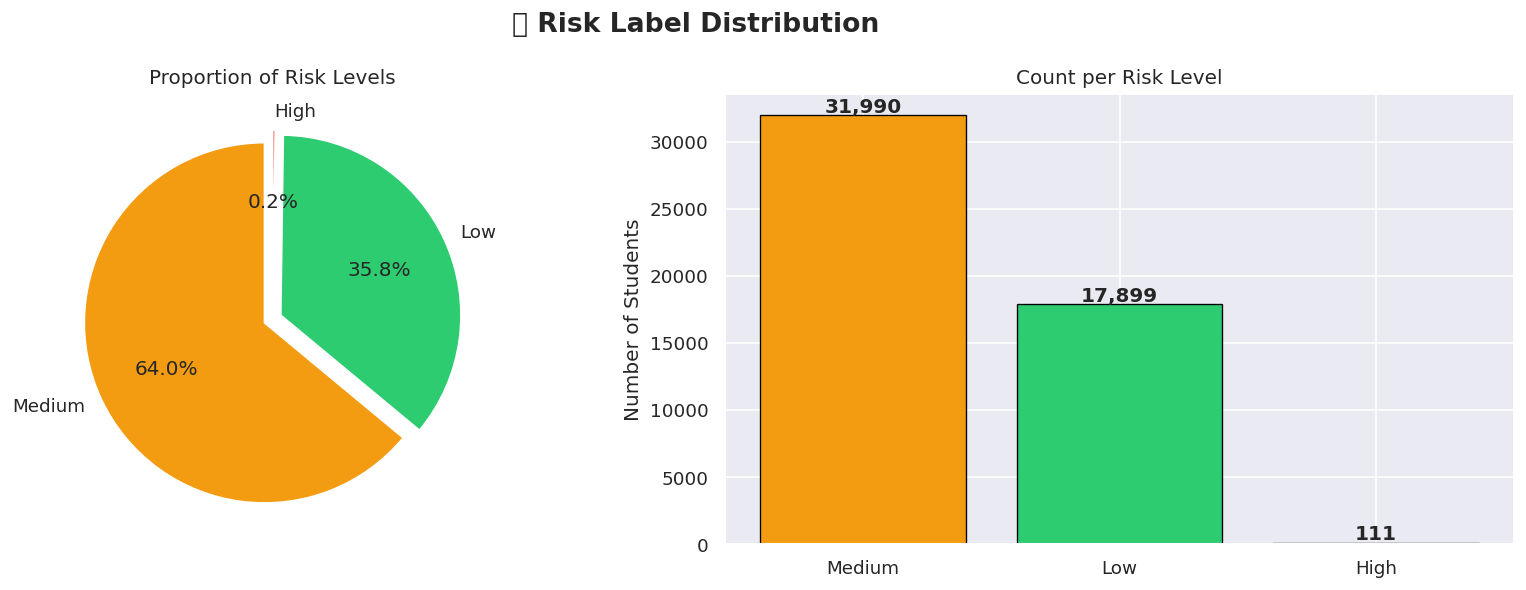

⚠️  NOTICE: Dataset is SEVERELY IMBALANCED — High risk only 111 students! We'll fix this with SMOTE.


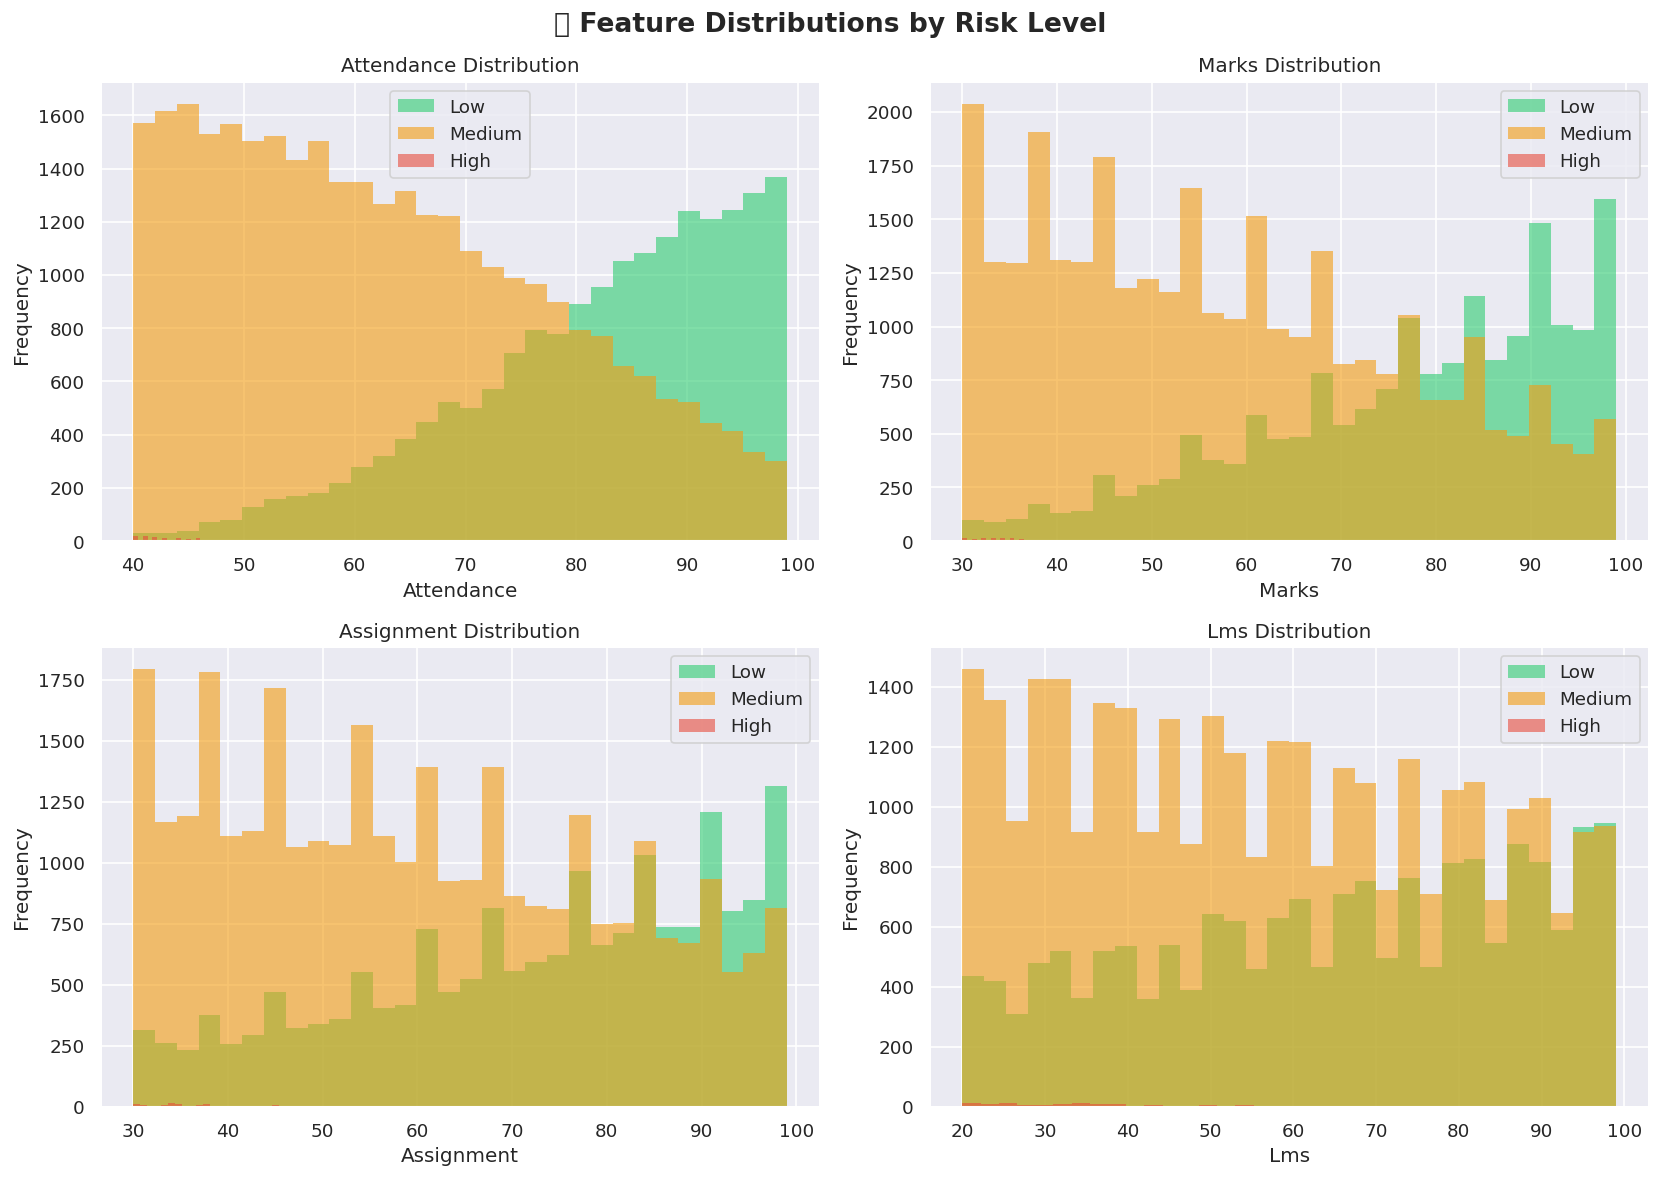

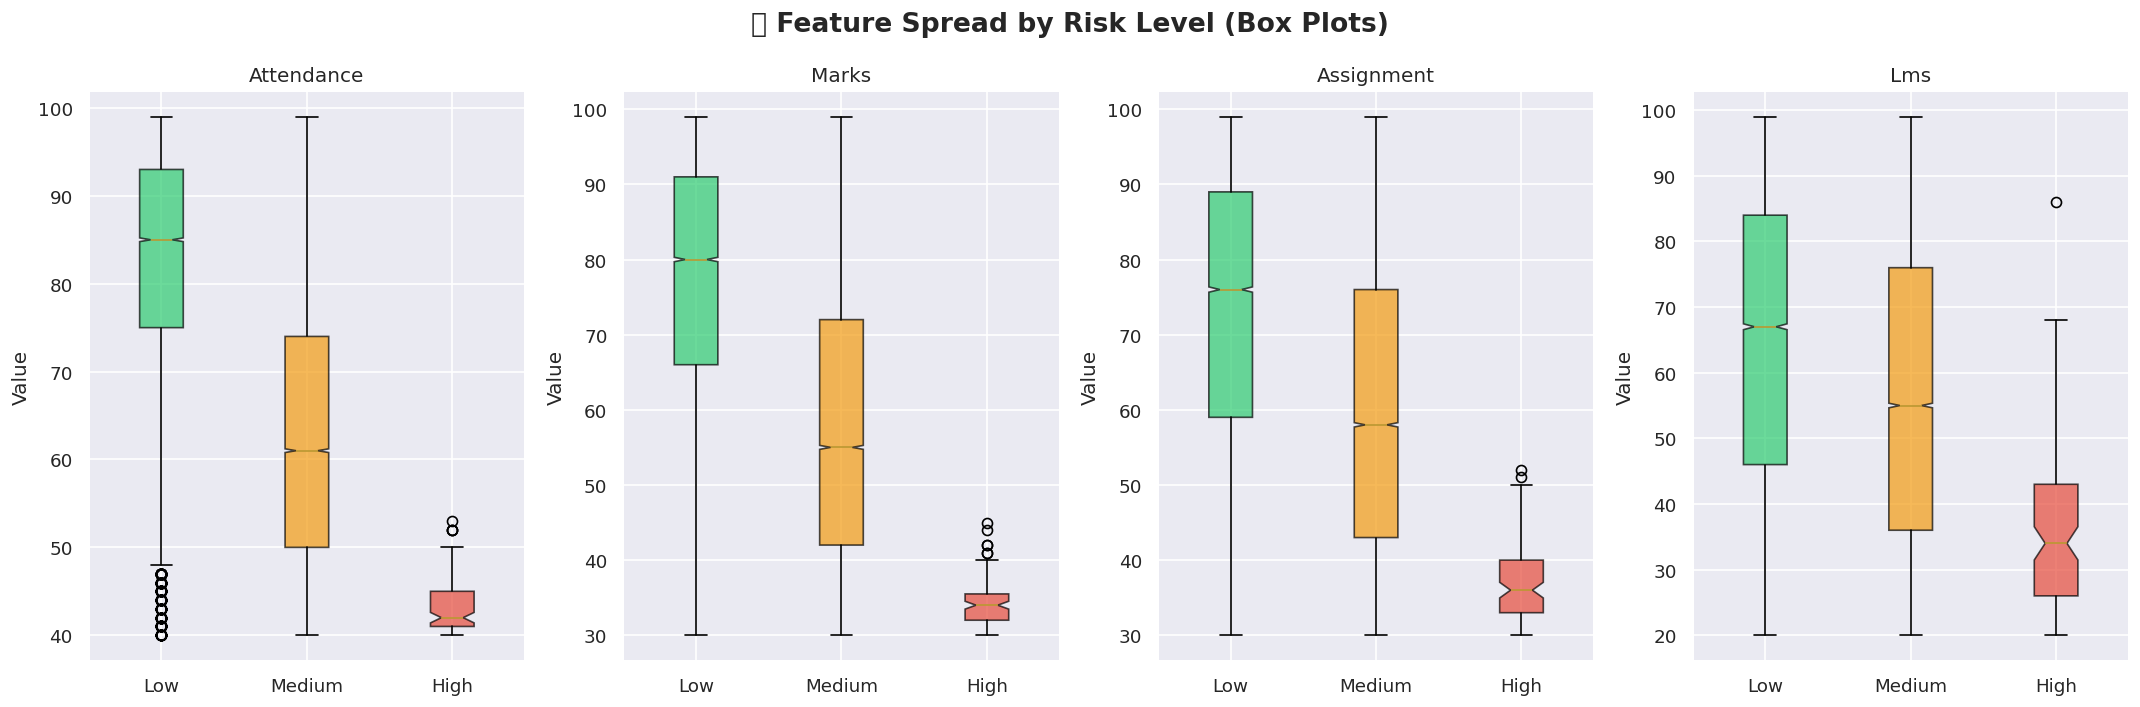

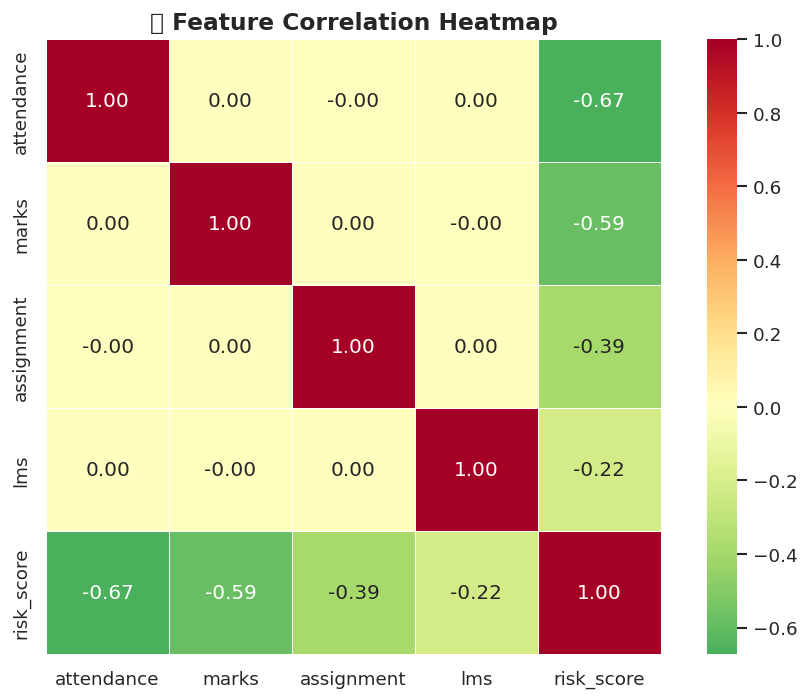

✅ EDA Complete!


In [3]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

sns.set_theme(style="darkgrid", palette="husl")
plt.rcParams['figure.dpi'] = 120

print("📊 Dataset Info:")
print(f"  Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
print(f"\n  Null values: {df.isnull().sum().sum()}")
print(f"\n  Risk Label Distribution:")
print(df['risk_label'].value_counts())

# ── Plot 1: Risk Label Distribution (Pie + Bar)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("📊 Risk Label Distribution", fontsize=16, fontweight='bold')

colors = {'Low': '#2ecc71', 'Medium': '#f39c12', 'High': '#e74c3c'}
label_counts = df['risk_label'].value_counts()

axes[0].pie(label_counts, labels=label_counts.index,
            autopct='%1.1f%%',
            colors=[colors[l] for l in label_counts.index],
            startangle=90, explode=[0.05]*len(label_counts))
axes[0].set_title("Proportion of Risk Levels")

axes[1].bar(label_counts.index, label_counts.values,
            color=[colors[l] for l in label_counts.index], edgecolor='black', linewidth=0.8)
axes[1].set_title("Count per Risk Level")
axes[1].set_ylabel("Number of Students")
for i, v in enumerate(label_counts.values):
    axes[1].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot_01_risk_distribution.png', bbox_inches='tight')
plt.show()
print("⚠️  NOTICE: Dataset is SEVERELY IMBALANCED — High risk only 111 students! We'll fix this with SMOTE.")

# ── Plot 2: Feature Distributions by Risk Level
features = ['attendance', 'marks', 'assignment', 'lms']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("📈 Feature Distributions by Risk Level", fontsize=16, fontweight='bold')
axes = axes.flatten()

for i, feat in enumerate(features):
    for label in ['Low', 'Medium', 'High']:
        subset = df[df['risk_label'] == label][feat]
        axes[i].hist(subset, bins=30, alpha=0.6, label=label,
                     color=colors[label], edgecolor='none')
    axes[i].set_title(f'{feat.capitalize()} Distribution')
    axes[i].set_xlabel(feat.capitalize())
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.savefig('plot_02_feature_distributions.png', bbox_inches='tight')
plt.show()

# ── Plot 3: Box plots per feature per risk label
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
fig.suptitle("📦 Feature Spread by Risk Level (Box Plots)", fontsize=16, fontweight='bold')

for i, feat in enumerate(features):
    data_to_plot = [df[df['risk_label'] == label][feat].values for label in ['Low', 'Medium', 'High']]
    bp = axes[i].boxplot(data_to_plot, labels=['Low', 'Medium', 'High'],
                         patch_artist=True, notch=True)
    for patch, color in zip(bp['boxes'], [colors['Low'], colors['Medium'], colors['High']]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[i].set_title(feat.capitalize())
    axes[i].set_ylabel('Value')

plt.tight_layout()
plt.savefig('plot_03_boxplots.png', bbox_inches='tight')
plt.show()

# ── Plot 4: Correlation Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[['attendance', 'marks', 'assignment', 'lms', 'risk_score']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r',
            center=0, ax=ax, linewidths=0.5, square=True)
ax.set_title("🔥 Feature Correlation Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_04_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print("✅ EDA Complete!")

🔧 Preprocessing data...
  Label Encoding: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

  Train size: 40,000  |  Test size: 10,000

  Applying SMOTE to fix class imbalance...
  Before SMOTE — {np.int64(0): np.int64(89), np.int64(1): np.int64(14319), np.int64(2): np.int64(25592)}
  After SMOTE  — {np.int64(0): np.int64(25592), np.int64(1): np.int64(25592), np.int64(2): np.int64(25592)}
  New train size: 76,776


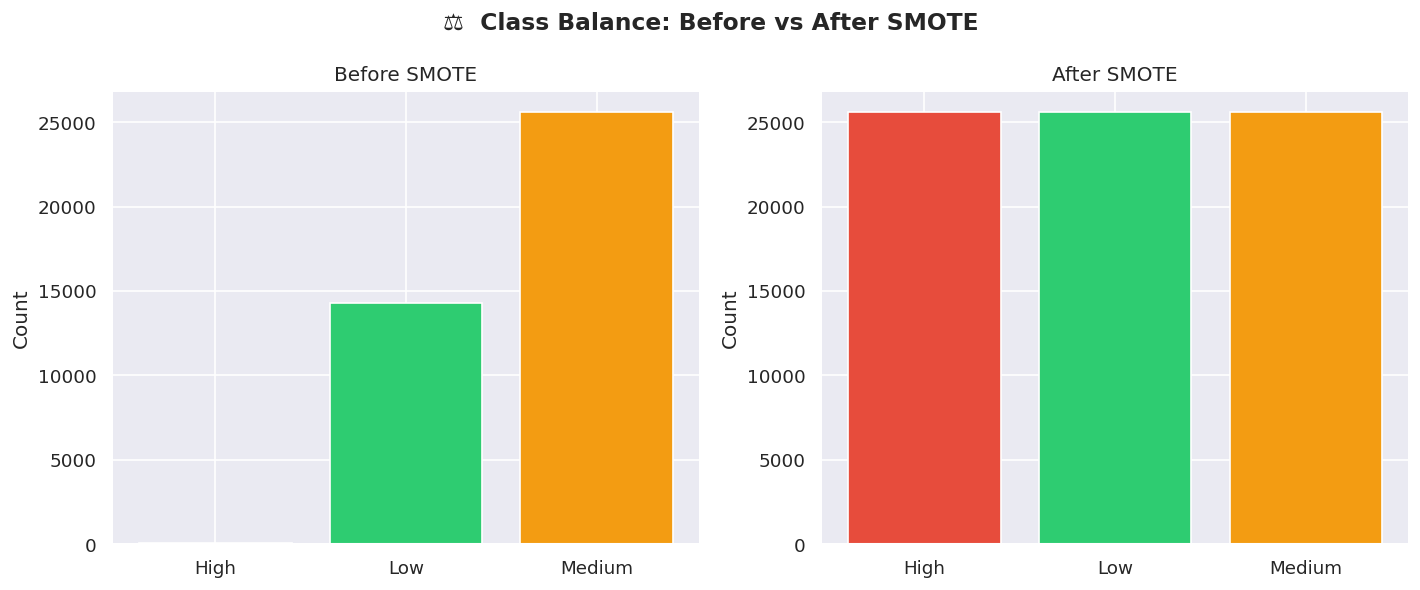

✅ Preprocessing complete!


In [4]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

print("🔧 Preprocessing data...")

# Features & Target
X = df[['attendance', 'marks', 'assignment', 'lms']].values
y_raw = df['risk_label'].values

# Encode labels: High=0, Low=1, Medium=2
le = LabelEncoder()
y = le.fit_transform(y_raw)
print(f"  Label Encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Train/Test Split BEFORE SMOTE (important! never SMOTE test data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\n  Train size: {X_train.shape[0]:,}  |  Test size: {X_test.shape[0]:,}")

# SMOTE — fix class imbalance on TRAIN only
print("\n  Applying SMOTE to fix class imbalance...")
print(f"  Before SMOTE — {dict(zip(*np.unique(y_train, return_counts=True)))}")

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print(f"  After SMOTE  — {dict(zip(*np.unique(y_train_res, return_counts=True)))}")
print(f"  New train size: {X_train_res.shape[0]:,}")

# Scale features (for LSTM later)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# ── Plot: Before vs After SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("⚖️  Class Balance: Before vs After SMOTE", fontsize=14, fontweight='bold')

before_counts = dict(zip(*np.unique(y_train, return_counts=True)))
after_counts = dict(zip(*np.unique(y_train_res, return_counts=True)))
label_names = le.classes_

axes[0].bar([label_names[k] for k in before_counts.keys()],
            list(before_counts.values()),
            color=[colors[l] for l in [label_names[k] for k in before_counts.keys()]])
axes[0].set_title("Before SMOTE")
axes[0].set_ylabel("Count")

axes[1].bar([label_names[k] for k in after_counts.keys()],
            list(after_counts.values()),
            color=[colors[l] for l in [label_names[k] for k in after_counts.keys()]])
axes[1].set_title("After SMOTE")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig('plot_05_smote_balance.png', bbox_inches='tight')
plt.show()

print("✅ Preprocessing complete!")

🚀 Training XGBoost Classifier...
  ✅ Training done in 9.79s

  🎯 Accuracy: 98.59%

  📋 Classification Report:
              precision    recall  f1-score   support

        High       0.86      0.86      0.86        22
         Low       0.97      0.99      0.98      3580
      Medium       0.99      0.98      0.99      6398

    accuracy                           0.99     10000
   macro avg       0.94      0.95      0.94     10000
weighted avg       0.99      0.99      0.99     10000

  📈 ROC-AUC Score (macro): 0.9996


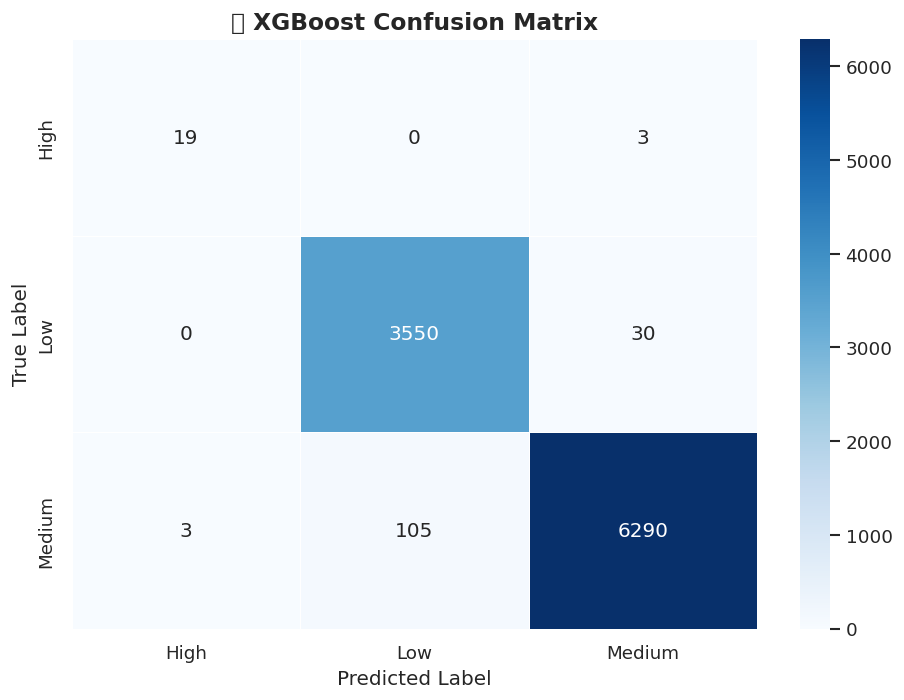

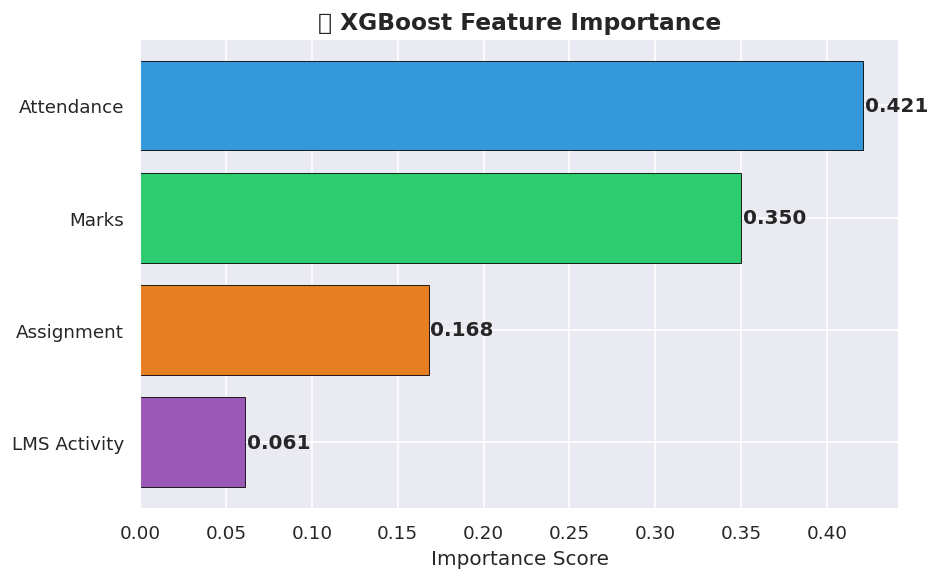

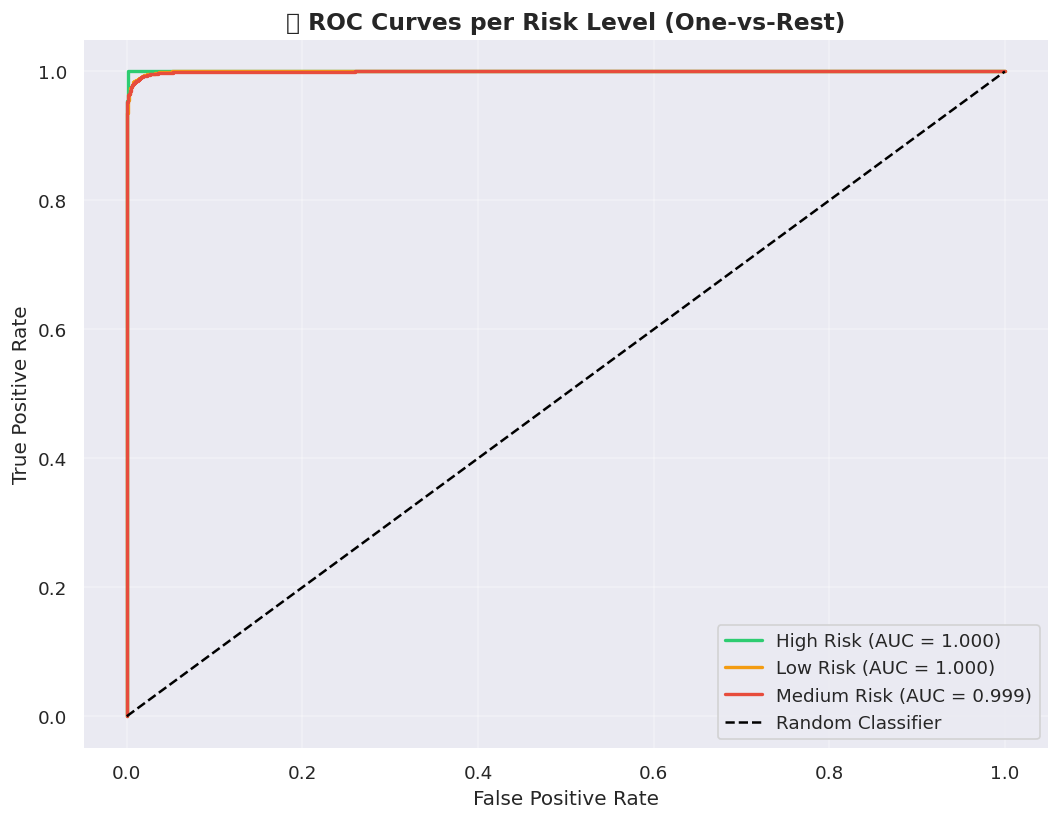

✅ XGBoost training & evaluation complete!


In [5]:
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, roc_auc_score)
from sklearn.preprocessing import label_binarize
import time

print("🚀 Training XGBoost Classifier...")

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

start = time.time()
xgb_model.fit(
    X_train_res, y_train_res,
    eval_set=[(X_test_scaled, y_test)],
    verbose=False
)
elapsed = time.time() - start
print(f"  ✅ Training done in {elapsed:.2f}s")

# Predictions
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)

# Metrics
acc = accuracy_score(y_test, y_pred)
print(f"\n  🎯 Accuracy: {acc*100:.2f}%")
print(f"\n  📋 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# ROC-AUC (multi-class, one-vs-rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
roc_auc = roc_auc_score(y_test_bin, y_prob, multi_class='ovr', average='macro')
print(f"  📈 ROC-AUC Score (macro): {roc_auc:.4f}")

# ── Plot 6: Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_,
            ax=ax, linewidths=0.5)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('🔷 XGBoost Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_06_confusion_matrix.png', bbox_inches='tight')
plt.show()

# ── Plot 7: Feature Importance (XGBoost built-in)
fig, ax = plt.subplots(figsize=(8, 5))
feat_names = ['Attendance', 'Marks', 'Assignment', 'LMS Activity']
importances = xgb_model.feature_importances_
sorted_idx = np.argsort(importances)

colors_bar = ['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
bars = ax.barh([feat_names[i] for i in sorted_idx],
               [importances[i] for i in sorted_idx],
               color=[colors_bar[i] for i in sorted_idx], edgecolor='black', linewidth=0.5)
ax.set_title('📊 XGBoost Feature Importance', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score')

for bar, val in zip(bars, [importances[i] for i in sorted_idx]):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot_07_feature_importance.png', bbox_inches='tight')
plt.show()

# ── Plot 8: ROC Curves (one-vs-rest per class)
from sklearn.metrics import roc_curve, auc
fig, ax = plt.subplots(figsize=(9, 7))
class_colors = ['#2ecc71', '#f39c12', '#e74c3c']

for i, (cls, col) in enumerate(zip(le.classes_, class_colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=col, lw=2, label=f'{cls} Risk (AUC = {roc_val:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('📈 ROC Curves per Risk Level (One-vs-Rest)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_08_roc_curves.png', bbox_inches='tight')
plt.show()

print("✅ XGBoost training & evaluation complete!")

🧠 Computing SHAP values (this may take ~1-2 min)...
  SHAP format: 3D array (500, 4, 3), split into 3 class arrays


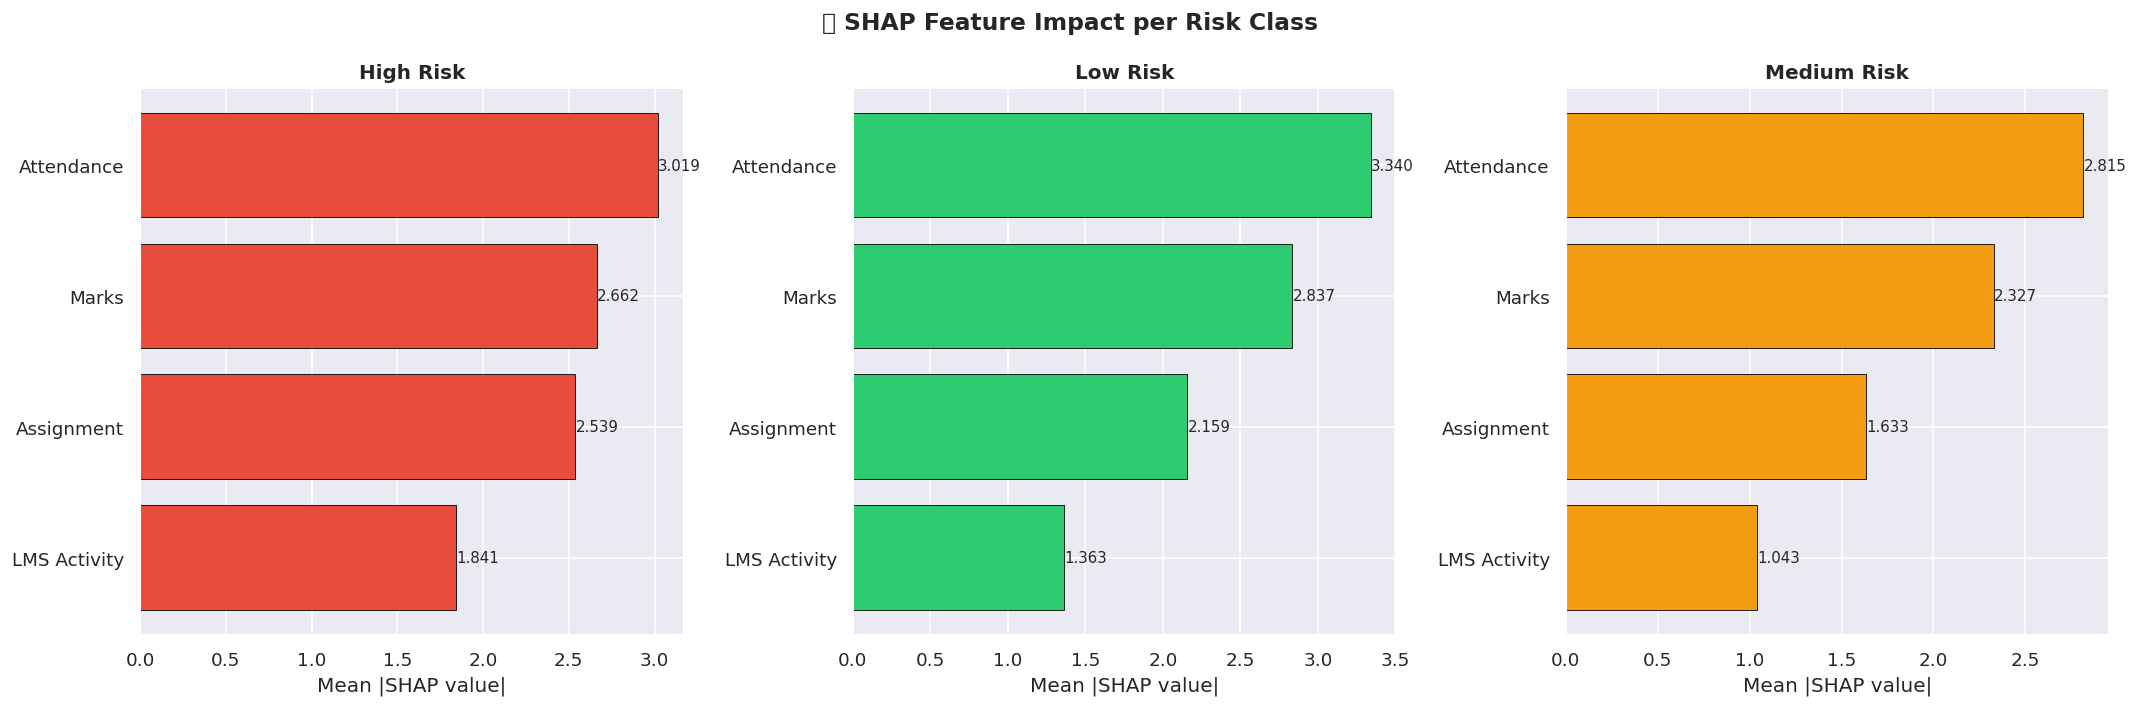

✅ Plot 9 done!

🔴 SHAP Beeswarm — Factors driving HIGH RISK classification:


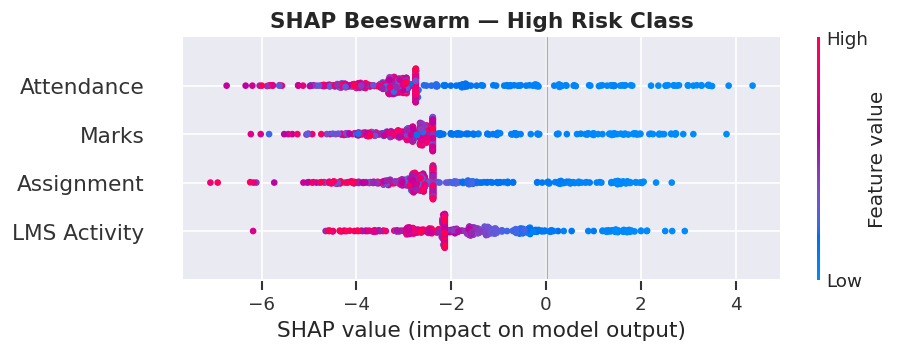

✅ Plot 10 done!

🟡 SHAP Beeswarm — Factors driving MEDIUM RISK classification:


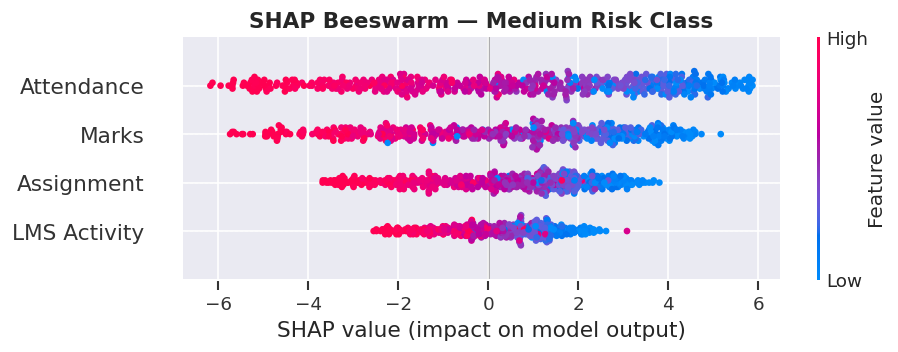

✅ Plot 11 done!

🔴 DEMO — HIGH RISK student (attendance=43, marks=34):
  Risk Label : High
  Confidence : {'High': '100.0%', 'Low': '0.0%', 'Medium': '0.0%'}
  Top Reasons:
    → 🔴 Attendance: 43 (↑ helping score, impact=3.417)
    → 🔴 Marks: 34 (↑ helping score, impact=3.265)
    → 🔴 LMS Activity: 28 (↑ helping score, impact=2.346)
    → 🔴 Assignment: 36 (↑ helping score, impact=1.422)

🟡 DEMO — MEDIUM RISK student (attendance=65, marks=55):
  Risk Label : Medium
  Confidence : {'High': '0.0%', 'Low': '0.0%', 'Medium': '100.0%'}
  Top Reasons:
    → 🔴 Marks: 55 (↑ helping score, impact=2.954)
    → 🔴 Attendance: 65 (↑ helping score, impact=2.564)
    → 🔴 Assignment: 60 (↑ helping score, impact=1.166)
    → 🔴 LMS Activity: 50 (↑ helping score, impact=0.973)

🟢 DEMO — LOW RISK student (attendance=90, marks=85):
  Risk Label : Low
  Confidence : {'High': '0.0%', 'Low': '100.0%', 'Medium': '0.0%'}
  Top Reasons:
    → 🔴 Attendance: 90 (↑ helping score, impact=3.989)
    → 🔴 Marks: 85 (↑ h

In [7]:
import shap
import numpy as np
import matplotlib.pyplot as plt

print("🧠 Computing SHAP values (this may take ~1-2 min)...")

explainer = shap.TreeExplainer(xgb_model)

# Sample 500 from test set
sample_idx = np.random.choice(len(X_test), size=min(500, len(X_test)), replace=False)
X_test_sample = X_test[sample_idx]

# Get raw SHAP output and detect its structure
shap_values_raw = explainer.shap_values(X_test_sample)

feat_names = ['Attendance', 'Marks', 'Assignment', 'LMS Activity']
class_names_list = ['High Risk', 'Low Risk', 'Medium Risk']
class_colors_local = ['#e74c3c', '#2ecc71', '#f39c12']

# ── Detect SHAP format (list-of-arrays vs 3D array)
if isinstance(shap_values_raw, list):
    # Old SHAP format: list of (n_samples, n_features) arrays, one per class
    shap_per_class = shap_values_raw          # shap_per_class[i] → (500, 4)
    print(f"  SHAP format: list of {len(shap_per_class)} arrays, each shape {shap_per_class[0].shape}")
else:
    # New SHAP format: single 3D array (n_samples, n_features, n_classes)
    shap_per_class = [shap_values_raw[:, :, i] for i in range(shap_values_raw.shape[2])]
    print(f"  SHAP format: 3D array {shap_values_raw.shape}, split into {len(shap_per_class)} class arrays")

# ── Plot 9: SHAP Bar Summary (Mean |SHAP| per class)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("🧠 SHAP Feature Impact per Risk Class", fontsize=14, fontweight='bold')

for i in range(3):
    sv = shap_per_class[i]                          # (500, 4)
    shap_mean = np.abs(sv).mean(axis=0)             # (4,)
    sorted_idx = np.argsort(shap_mean)
    axes[i].barh(
        [feat_names[j] for j in sorted_idx],
        shap_mean[sorted_idx],
        color=class_colors_local[i],
        edgecolor='black', linewidth=0.5
    )
    axes[i].set_title(class_names_list[i], fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Mean |SHAP value|')
    # Annotate values
    for bar_idx, val in enumerate(shap_mean[sorted_idx]):
        axes[i].text(val + 0.001, bar_idx, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('plot_09_shap_per_class.png', bbox_inches='tight')
plt.show()
print("✅ Plot 9 done!")

# ── Plot 10: SHAP Beeswarm — High Risk class (FIXED)
print("\n🔴 SHAP Beeswarm — Factors driving HIGH RISK classification:")
sv_high = shap_per_class[0]   # (500, 4) — High Risk class

shap.summary_plot(
    sv_high,                   # (500, 4) — correct shape now
    X_test_sample,             # (500, 4)
    feature_names=feat_names,
    plot_type='dot',
    show=False
)
plt.title("SHAP Beeswarm — High Risk Class", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_10_shap_beeswarm_highrisk.png', bbox_inches='tight')
plt.show()
print("✅ Plot 10 done!")

# ── Plot 11 BONUS: Beeswarm for Medium Risk (also useful for dashboard)
print("\n🟡 SHAP Beeswarm — Factors driving MEDIUM RISK classification:")
sv_med = shap_per_class[2]   # Medium Risk

shap.summary_plot(
    sv_med,
    X_test_sample,
    feature_names=feat_names,
    plot_type='dot',
    show=False
)
plt.title("SHAP Beeswarm — Medium Risk Class", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_11_shap_beeswarm_mediumrisk.png', bbox_inches='tight')
plt.show()
print("✅ Plot 11 done!")

# ── Explainability Function (FastAPI will call this)
def explain_student_risk(student_features: dict) -> dict:
    """
    Input:  {'attendance': 43, 'marks': 34, 'assignment': 36, 'lms': 28}
    Output: risk label + confidence + top contributing reasons
    """
    X_input = np.array([[
        student_features['attendance'],
        student_features['marks'],
        student_features['assignment'],
        student_features['lms']
    ]])

    pred_label_idx = xgb_model.predict(X_input)[0]
    pred_proba     = xgb_model.predict_proba(X_input)[0]
    pred_label     = le.inverse_transform([pred_label_idx])[0]

    # SHAP for this single student
    sv_single_raw = explainer.shap_values(X_input)

    # Handle both SHAP formats
    if isinstance(sv_single_raw, list):
        sv_for_class = sv_single_raw[pred_label_idx][0]   # (4,)
    else:
        sv_for_class = sv_single_raw[0, :, pred_label_idx]  # (4,)

    # Sort features by absolute SHAP impact
    feature_impact = sorted(
        zip(feat_names, X_input[0], sv_for_class),
        key=lambda x: abs(x[2]), reverse=True
    )

    reasons = []
    for fname, fval, fshap in feature_impact:
        direction = "↓ hurting" if fshap < 0 else "↑ helping"
        severity  = "🔴" if abs(fshap) > 0.3 else ("🟡" if abs(fshap) > 0.1 else "🟢")
        reasons.append(f"{severity} {fname}: {int(fval)} ({direction} score, impact={fshap:.3f})")

    confidence = {
        le.inverse_transform([i])[0]: f"{p*100:.1f}%"
        for i, p in enumerate(pred_proba)
    }

    return {
        "risk_label":  pred_label,
        "confidence":  confidence,
        "top_reasons": reasons
    }

# ── DEMO 1: High Risk Student
print("\n" + "="*60)
print("🔴 DEMO — HIGH RISK student (attendance=43, marks=34):")
print("="*60)
r1 = explain_student_risk({'attendance': 43, 'marks': 34, 'assignment': 36, 'lms': 28})
print(f"  Risk Label : {r1['risk_label']}")
print(f"  Confidence : {r1['confidence']}")
print(f"  Top Reasons:")
for r in r1['top_reasons']:
    print(f"    → {r}")

# ── DEMO 2: Medium Risk Student
print("\n" + "="*60)
print("🟡 DEMO — MEDIUM RISK student (attendance=65, marks=55):")
print("="*60)
r2 = explain_student_risk({'attendance': 65, 'marks': 55, 'assignment': 60, 'lms': 50})
print(f"  Risk Label : {r2['risk_label']}")
print(f"  Confidence : {r2['confidence']}")
print(f"  Top Reasons:")
for r in r2['top_reasons']:
    print(f"    → {r}")

# ── DEMO 3: Low Risk Student
print("\n" + "="*60)
print("🟢 DEMO — LOW RISK student (attendance=90, marks=85):")
print("="*60)
r3 = explain_student_risk({'attendance': 90, 'marks': 85, 'assignment': 88, 'lms': 75})
print(f"  Risk Label : {r3['risk_label']}")
print(f"  Confidence : {r3['confidence']}")
print(f"  Top Reasons:")
for r in r3['top_reasons']:
    print(f"    → {r}")

print("\n✅ SHAP Explainability Engine fully working!")
print("✅ explain_student_risk() function ready for FastAPI integration!")

🔁 Running 5-Fold Cross Validation...

  CV Fold Scores: ['98.80%', '98.71%', '98.54%', '98.70%', '98.84%']
  Mean Accuracy : 98.72%
  Std Dev       : ±0.10%


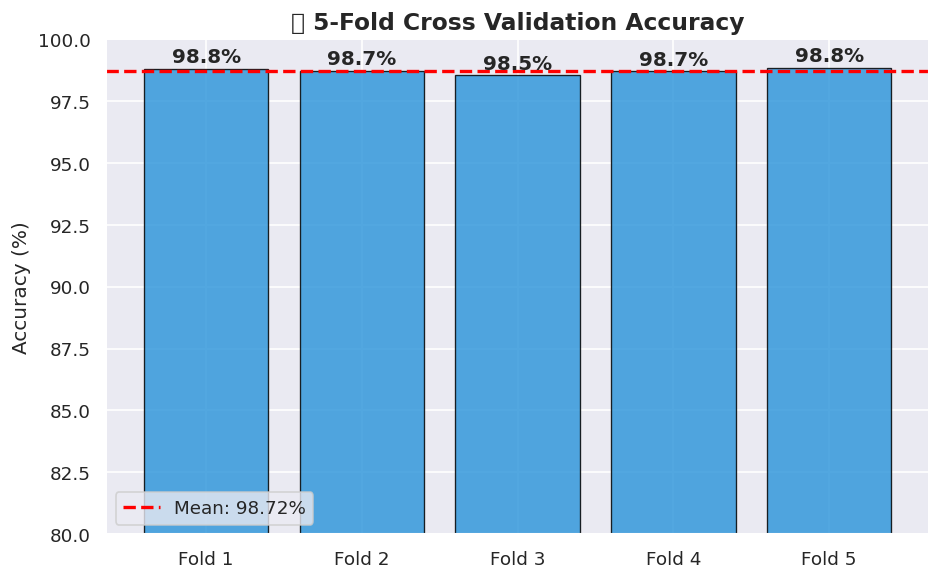

✅ Cross validation complete!


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

print("🔁 Running 5-Fold Cross Validation...")

# Note: Using original X, y (before SMOTE) for honest CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"\n  CV Fold Scores: {[f'{s*100:.2f}%' for s in cv_scores]}")
print(f"  Mean Accuracy : {cv_scores.mean()*100:.2f}%")
print(f"  Std Dev       : ±{cv_scores.std()*100:.2f}%")

# ── Plot 11: CV scores
fig, ax = plt.subplots(figsize=(8, 5))
folds = [f'Fold {i+1}' for i in range(5)]
bars = ax.bar(folds, cv_scores * 100, color='#3498db', edgecolor='black',
              linewidth=0.8, alpha=0.85)
ax.axhline(cv_scores.mean() * 100, color='red', linestyle='--',
           linewidth=2, label=f'Mean: {cv_scores.mean()*100:.2f}%')
ax.set_ylim(80, 100)
ax.set_ylabel('Accuracy (%)')
ax.set_title('🔁 5-Fold Cross Validation Accuracy', fontsize=14, fontweight='bold')
ax.legend()

for bar, val in zip(bars, cv_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{val*100:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('plot_11_cross_validation.png', bbox_inches='tight')
plt.show()

print("✅ Cross validation complete!")